# The estimator ladder: from historical simulation to GARCH, EVT, CAViaR and GAS-FZ

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (VaR, ES and a first exceedance count)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- name the rungs of the ladder of VaR and ES estimators Contraste runs, from historical simulation to the dynamic semiparametric models, and say what each one assumes;
- check from a committed artifact that every forecast was made with information dated before its day and that the hyperparameters were fixed before the windows they are scored on;
- run the closed-form rungs (age-weighted simulation, EWMA, delta-normal, Cornish-Fisher, filtered historical simulation and the peaks-over-threshold tail) on real returns with the engine's functions and check the committed EWMA forecast against its own recursion;
- say which rungs cannot be refitted in a notebook and why, and read their fitted parameters and convergence failures from the committed ladder;
- read, for six market windows, how often each rung exceeded its 1 percent VaR, and which rungs the eligibility gates removed.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C11 as Contraste commits it: one document per market window plus the document of the ladder itself.

- `data/derived/C11/models-ladder.json`: the 18 entries of the ladder (17 fitted rungs and one challenger that was not run), each with its source, innovation, estimation window, refit frequency and, per window, the number of refits, convergence failures and the range of its fitted parameters.
- `data/derived/C11/<window>.json` for the six windows: `calm-2004-06`, `equity-2007-09`, `equity-2020`, `rates-2022`, `fx-2008` and `mixed-2023`. Each holds, for every model and tail level, the VaR and ES path, the exceedance days and the eligibility verdict.

Licence classes decide what is committed. Of the six windows only `rates-2022` and `fx-2008` commit the realised losses (Treasury and Federal Reserve H.10 data, `mirror-allowed`); the equity and mixed windows hold the Kenneth French return, `derived-only`, so they commit forecasts and exceedance days but not returns. The estimators cannot be refitted on a window whose estimation returns are not committed, and for no window are the 1,000 estimation days committed. The notebook therefore reads the committed forecasts of the fitted rungs and runs the closed-form rungs on the 251 realised returns of `fx-2008`, saying each time what that changes. The next cell loads the seven files.

In [2]:
# Load the ladder document and the six window documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C11 = ROOT / "data" / "derived" / "C11"
ladder_doc = json.loads((C11 / "models-ladder.json").read_text(encoding="utf-8"))
WINDOWS = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
windows = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in WINDOWS}

print("ladder baked by riskvalidation", ladder_doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
for w, doc in windows.items():
    out = doc["outputs"]
    print(f"{w:15s} {out['window']['start_date']} to {out['window']['end_date']} | {out['window']['n_forecast_days']:4d} days | "
          f"realised losses {out['grid']['realised_loss']['status']}")

ladder baked by riskvalidation 0.7.0 | installed 0.8.1
calm-2004-06    2004-01-02 to 2006-12-29 |  750 days | realised losses withheld-derived-only
equity-2007-09  2007-07-02 to 2009-06-30 |  504 days | realised losses withheld-derived-only
equity-2020     2020-02-03 to 2020-06-30 |  104 days | realised losses withheld-derived-only
rates-2022      2022-01-03 to 2022-12-30 |  249 days | realised losses included
fx-2008         2008-07-01 to 2009-06-30 |  251 days | realised losses included
mixed-2023      2023-03-01 to 2023-05-31 |   64 days | realised losses withheld-derived-only


## Method

### Step 1: the ladder

A rung is one way of turning past returns into tomorrow's VaR and ES. The ladder runs from the transparent baseline to the current academic frontier, so a validator can ask of any complex rung whether it beats the simple one it replaces. The ladder document lists each rung with its source, the distribution it assumes for the innovations (`innovation`), how many past days it reads and how often it is refitted. The next cell prints it. The last entry, `nn-fz`, is a neural challenger of the literature that the bake does **not** train; the document says so instead of leaving it out.

In [3]:
# Print the ladder: rung, estimator, innovation, days read, refit period and whether it forecasts an ES
YES_NO = {True: "yes", False: "no"}
print(f"{'model':11s} {'rung':5s} {'innovation':12s} {'days':>5s} {'refit':>5s} {'ES':>3s}  status")
for entry in ladder_doc["fit"]["ladder"]:
    days = entry["estimation_window_days"] if entry["estimation_window_days"] is not None else "-"
    refit = entry["refit_every_days"] if entry["refit_every_days"] is not None else "-"
    print(f"{entry['model_id']:11s} {entry['rung']:5s} {entry['innovation']:12s} {days!s:>5s} {refit!s:>5s} {YES_NO[entry['forecasts_es']]:>3s}  {entry['status']}")
challenger = ladder_doc["fit"]["ladder"][-1]
print("not run:", challenger["model_id"], "|", challenger["source"])

model       rung  innovation    days refit  ES  status
hs-250      R1    empirical      250     1 yes  fitted
hs-500      R1    empirical      500     1 yes  fitted
awhs        R2    empirical      250     1 yes  fitted
dn-rolling  R3    normal        1000     1 yes  fitted
cf-rolling  R3    normal        1000     1  no  fitted
ewma        R4    normal        1000     1 yes  fitted
garch-t     R5    student-t     1000     1 yes  fitted
gjr-t       R5    student-t     1000     1 yes  fitted
egarch-t    R5    student-t     1000     1 yes  fitted
fhs         R6    empirical     1000     1 yes  fitted
evt-mf      R7    gpd-tail      1000     1 yes  fitted
caviar-sav  R8    none          1000     5  no  fitted
caviar-as   R8    none          1000     5  no  fitted
caviar-es   R8    none          1000     5 yes  fitted
gas-fz-1    R9    none          1000    20 yes  fitted
gas-fz-2    R9    none          1000    20 yes  fitted
gas-hybrid  R9    none          1000    20 yes  fitted
nn-fz     

### Step 2: no look-ahead, hyperparameters fixed in advance

Two rules make a back-test honest. First, every forecast uses only returns dated **before** its day: each window document records, for each forecast date, the first and last day of the estimation sample (`grid.estimation_start`, `grid.estimation_end`). Second, the hyperparameters (the EWMA decay, the age-weighting decay, the EVT threshold fraction, the number of optimiser starts) are chosen on a span that ends before every window starts, never on the window being scored (`hyperparameters.fixed_on`, `tuned_on_test_window`). Both rules are checkable from the committed file, which the next cell does for the six windows.

In [4]:
# Check the two rules on every window: the estimation sample ends before each forecast date, the hyperparameters before the window
for w, doc in windows.items():
    out = doc["outputs"]
    grid, hyper = out["grid"], out["hyperparameters"]
    before = all(end < day for end, day in zip(grid["estimation_end"], grid["dates"]))
    fixed_before = hyper["fixed_on"]["end"] < out["window"]["start_date"]
    print(f"{w:15s} scheme {grid['scheme']} {grid['estimation_window_days']} days | every estimation sample ends before its day: {before} | "
          f"hyperparameters fixed on {hyper['fixed_on']['start']} to {hyper['fixed_on']['end']}, before the window: {fixed_before} | "
          f"tuned on the test window: {hyper['tuned_on_test_window']}")

hyper = windows["fx-2008"]["outputs"]["hyperparameters"]
print({key: hyper[key] for key in ("ewma_lambda", "age_weight_lambda", "evt_threshold_fraction", "garch_refit_every_days", "caviar_n_starts", "gas_n_starts", "seed")})

calm-2004-06    scheme rolling 1000 days | every estimation sample ends before its day: True | hyperparameters fixed on 1995-01-01 to 2003-12-31, before the window: True | tuned on the test window: False
equity-2007-09  scheme rolling 1000 days | every estimation sample ends before its day: True | hyperparameters fixed on 1995-01-01 to 2003-12-31, before the window: True | tuned on the test window: False
equity-2020     scheme rolling 1000 days | every estimation sample ends before its day: True | hyperparameters fixed on 1995-01-01 to 2003-12-31, before the window: True | tuned on the test window: False
rates-2022      scheme rolling 1000 days | every estimation sample ends before its day: True | hyperparameters fixed on 1995-01-01 to 2003-12-31, before the window: True | tuned on the test window: False
fx-2008         scheme rolling 1000 days | every estimation sample ends before its day: True | hyperparameters fixed on 1995-01-01 to 2003-12-31, before the window: True | tuned on the

### Step 3: age-weighted historical simulation (rung R2)

Plain historical simulation gives every day of the window the same weight, so a crisis day leaves the window all at once and the VaR jumps. Boudoukh, Richardson and Whitelaw (1998) weight the return observed $i$ days ago by

$$w_i = \frac{1-\lambda}{1-\lambda^{K}}\,\lambda^{\,i-1}, \qquad i = 1,\dots,K$$

sort the returns, accumulate the weights until they reach $\alpha$, and interpolate. The engine's `age_weights(lam, k)` returns the weights and `age_weighted_var_es(returns, alpha, lam, window)` the forecast; the ES is the tail integral of the same interpolated quantile function (the paper gives no ES rule, the engine documents this as its decision D-9). We use the committed $\lambda$ and the first 100 returns of `fx-2008`, which is a shorter window than the committed $K = 250$, and compare with the equally weighted forecast at the 2.5 percent level, where the tail holds 2.5 observations.

In [5]:
# Age weights with the committed decay, and the age-weighted forecast against the equally weighted one on the same 100 returns
from riskvalidation.market.historical import age_weighted_var_es, age_weights, historical_var_es

fx_out = windows["fx-2008"]["outputs"]
y = -np.array(fx_out["grid"]["realised_loss"]["loss"])      # the 251 realised returns, engine convention
lam_age = fx_out["hyperparameters"]["age_weight_lambda"]
K = 100
weights = age_weights(lam_age, K)
print(f"lambda {lam_age}, K {K}: weights sum to {weights.sum():.6f} | newest day {weights[0]:.5f} | oldest day {weights[-1]:.5f}")
print(f"effective number of days 1 / sum(w^2): {1 / np.sum(weights ** 2):.1f} of {K}")

sample = y[:K]
for alpha in (0.01, 0.025):
    var_eq, es_eq = historical_var_es(sample, alpha, K)
    var_aw, es_aw = age_weighted_var_es(sample, alpha, lam_age, K)
    print(f"alpha {alpha}: equal weights VaR {-var_eq:.6f} ES {-es_eq:.6f} | age weights VaR {-var_aw:.6f} ES {-es_aw:.6f}")

lambda 0.99, K 100: weights sum to 1.000000 | newest day 0.01577 | oldest day 0.00583
effective number of days 1 / sum(w^2): 92.4 of 100
alpha 0.01: equal weights VaR 0.022293 ES 0.022293 | age weights VaR 0.022072 ES 0.022246
alpha 0.025: equal weights VaR 0.020861 ES 0.021771 | age weights VaR 0.021324 ES 0.021933


### Step 4: EWMA, and a check of the committed forecast against its own recursion (rung R4)

RiskMetrics models the variance of tomorrow's return as an exponentially weighted average of squared returns, with a zero mean (the zero mean is part of the method):

$$\sigma^2_{t+1\mid t} = \lambda\,\sigma^2_{t\mid t-1} + (1-\lambda)\,r_t^2, \qquad K = \frac{\ln \varepsilon}{\ln \lambda}$$

where $K$ is the number of days that carry a weight above the tolerance $\varepsilon$ (RiskMetrics Technical Document, section 5.3.2). The VaR and ES then come from the normal distribution with that variance (delta-normal, rung R3):

$$v = \mu + \Phi^{-1}(\alpha)\,\sigma, \qquad e = \mu - \sigma\,\frac{\varphi(\Phi^{-1}(\alpha))}{\alpha}$$

This rung is a good place to check a committed artifact, because it has one free input only. With $\mu = 0$, the committed VaR of each day fixes $\sigma_t$, and the committed ES must then equal the formula above (two numbers, one unknown: the check can fail). Then the recursion, started from the first committed variance and fed the realised returns, must reproduce the whole committed path. The next cell does both with the engine's `delta_normal_var_es`, `ewma_variance` and `ewma_effective_days`.

In [6]:
# Recover sigma from the committed EWMA VaR, check the committed ES against delta-normal, and replay the recursion on the realised returns
from riskvalidation.market.parametric import delta_normal_var_es, ewma_effective_days, ewma_variance

ewma = {m["model_id"]: m for m in fx_out["models"]}["ewma"]["by_level"][0]      # level alpha = 0.01
alpha = ewma["alpha"]
var_loss, es_loss = np.array(ewma["var"]), np.array(ewma["es"])
sigma = var_loss / -stats.norm.ppf(alpha)                    # mu = 0: the committed VaR fixes sigma day by day
engine_pairs = np.array([delta_normal_var_es(0.0, s, alpha) for s in sigma])
print("committed ES equals the delta-normal ES for the sigma the VaR implies: max difference", f"{np.max(np.abs(-engine_pairs[:, 1] - es_loss)):.2e}")

lam = fx_out["hyperparameters"]["ewma_lambda"]
replay = np.sqrt(ewma_variance(y[:-1], lam, sigma[0] ** 2))     # element t is the forecast for day t, from returns up to t - 1
print(f"lambda {lam} | days that carry a weight above 1%: {ewma_effective_days(lam, 0.01):.1f}")
print(f"replayed sigma against committed sigma: max relative difference {np.max(np.abs(replay - sigma) / sigma):.2e} over {sigma.size} days")
print(f"sigma first day {sigma[0]:.6f} | last day {sigma[-1]:.6f} | largest {sigma.max():.6f} on day {int(sigma.argmax())}")

committed ES equals the delta-normal ES for the sigma the VaR implies: max difference 1.00e-10
lambda 0.97 | days that carry a weight above 1%: 151.2
replayed sigma against committed sigma: max relative difference 5.92e-09 over 251 days
sigma first day 0.006266 | last day 0.008828 | largest 0.014629 on day 119


### Step 5: Cornish-Fisher (rung R3)

The delta-normal rung under-covers when returns have fat tails or skew. The Cornish-Fisher expansion corrects the normal quantile $z = \Phi^{-1}(\alpha)$ with the skewness $S$ and the excess kurtosis $K_e$ of the returns:

$$z_{CF} = z + \frac{(z^2-1)S}{6} + \frac{(z^3-3z)K_e}{24} - \frac{(2z^3-5z)S^2}{36}, \qquad v = \mu + z_{CF}\,\sigma$$

The expansion is not monotone for large $S$ and $K_e$, so a forecast must report whether it is in its validity domain; the engine's `cornish_fisher_var` returns `valid`. It gives a VaR and no ES, which is why the committed `cf-rolling` has no FZ0 score (notebook 05). We compare the three VaR estimates on the sample moments of the 251 returns.

In [7]:
# Cornish-Fisher VaR from the sample moments, against delta-normal and the empirical quantile
from riskvalidation.market.conventions import var_es_from_sample
from riskvalidation.market.parametric import cornish_fisher_var

mu, sd = float(y.mean()), float(y.std())
skew, excess = float(stats.skew(y)), float(stats.kurtosis(y))          # Fisher definition: excess kurtosis
print(f"mean {mu:.6f} | standard deviation {sd:.6f} | skewness {skew:.3f} | excess kurtosis {excess:.3f}")
for alpha in (0.01, 0.025):
    cf = cornish_fisher_var(mu, sd, skew, excess, alpha)
    normal_var, normal_es = delta_normal_var_es(mu, sd, alpha)
    empirical_var, empirical_es = var_es_from_sample(y, alpha)
    print(f"alpha {alpha}: z {stats.norm.ppf(alpha):.3f} -> z_CF {cf.z_cf:.3f} | VaR normal {-normal_var:.6f}, Cornish-Fisher {-cf.var:.6f}, "
          f"empirical {-empirical_var:.6f} | expansion valid: {cf.valid}")

mean -0.000407 | standard deviation 0.010608 | skewness 0.629 | excess kurtosis 2.129
alpha 0.01: z -2.326 -> z_CF -2.212 | VaR normal 0.025085, Cornish-Fisher 0.023873, empirical 0.023915 | expansion valid: True
alpha 0.025: z -1.960 -> z_CF -1.750 | VaR normal 0.021198, Cornish-Fisher 0.018974, empirical 0.020861 | expansion valid: True


### Step 6: filtered historical simulation and the peaks-over-threshold tail (rungs R6 and R7)

Both rungs first **filter** the returns, dividing each by the volatility forecast made before it, $z_t = r_t/\sigma_t$, so the standardised residuals are close to identically distributed. Filtered historical simulation (Barone-Adesi, Giannopoulos and Vosper, 1999) then rescales those residuals with tomorrow's volatility, $r^*_s = \mu_{T+1} + \sigma_{T+1} z_s$, and reads the VaR and ES of the scenarios. Conditional EVT (McNeil and Frey, 2000) instead fits a generalised Pareto distribution to the excesses of the loss residuals $-z_t$ above a threshold $u$ (the $1-f$ quantile) and extrapolates; with $N_u$ exceedances out of $n$ and $q = 1-\alpha$,

$$\hat z_q = u + \frac{\hat\beta}{\hat\xi}\left[\left(\tfrac{n}{N_u}(1-q)\right)^{-\hat\xi} - 1\right], \qquad \widehat{\mathrm{ES}}_q = \frac{\hat z_q}{1-\hat\xi} + \frac{\hat\beta - \hat\xi u}{1-\hat\xi} \quad (\hat\xi<1)$$

The committed rungs filter with a GARCH model, which needs the optional package `arch` that this environment does not install. Here the filter is the EWMA volatility path recovered in step 4, which exercises the same engine functions (`filtered_hs_var_es`, `fit_gpd`, `evt_var_es`, `threshold_stability`) on real residuals; the numbers are those of an EWMA-filtered rung on 251 days, not of the committed `fhs` or `evt-mf`. The last table shows the model risk usually named for EVT: the shape $\hat\xi$ depends on the threshold.

In [8]:
# Standardise the returns with the EWMA volatility, then forecast with filtered historical simulation and a GPD tail
from riskvalidation.market.evt import evt_var_es, fit_gpd, threshold_stability
from riskvalidation.market.historical import filtered_hs_var_es

residuals = y / sigma                                   # each return over the volatility forecast made before it
print(f"standardised residuals: mean {residuals.mean():.3f} | standard deviation {residuals.std():.3f} | minimum {residuals.min():.3f}")
fraction = fx_out["hyperparameters"]["evt_threshold_fraction"]
tail = fit_gpd(-residuals, fraction)                    # loss residuals: the right tail is the loss tail
print(f"GPD at threshold fraction {fraction}: u {tail.threshold:.3f}, shape xi {tail.xi:.3f}, scale beta {tail.beta:.3f}, {tail.n_exceed} exceedances of {tail.n}")
for alpha in (0.01, 0.025):
    fhs_var, fhs_es = filtered_hs_var_es(residuals, 0.0, sigma[-1], alpha)
    z_q, es_q = evt_var_es(tail, 1.0 - alpha)
    normal_var, normal_es = delta_normal_var_es(0.0, sigma[-1], alpha)
    print(f"alpha {alpha}: VaR (ES) next day | normal {-normal_var:.5f} ({-normal_es:.5f}) | filtered HS {-fhs_var:.5f} ({-fhs_es:.5f}) | "
          f"EVT {sigma[-1] * z_q:.5f} ({sigma[-1] * es_q:.5f})")

print("threshold fraction, shape xi, exceedances:")
for f, xi, n_u in threshold_stability(-residuals, np.array([0.04, 0.05, 0.06, 0.08, 0.10])):
    print(f"  {f:.2f}  {xi:7.3f}  {n_u:3d}")

standardised residuals: mean -0.069 | standard deviation 1.070 | minimum -3.590
GPD at threshold fraction 0.05: u 1.789, shape xi 0.235, scale beta 0.323, 13 exceedances of 251
alpha 0.01: VaR (ES) next day | normal 0.02054 (0.02353) | filtered HS 0.02353 (0.02702) | EVT 0.02152 (0.02701)
alpha 0.025: VaR (ES) next day | normal 0.01730 (0.02064) | filtered HS 0.01780 (0.02233) | EVT 0.01806 (0.02248)
threshold fraction, shape xi, exceedances:
  0.04    0.452   10
  0.05    0.235   13
  0.06    0.204   15
  0.08    0.045   20
  0.10   -0.027   25


### Step 7: the rungs that cannot be refitted here, read from the ladder

Three families need more than a notebook can reproduce from committed files, and the document of the ladder is the evidence for them.

- **GARCH family (R5):** $\sigma_t^2 = \omega + \alpha_1\varepsilon_{t-1}^2 + \beta_1\sigma_{t-1}^2$ (Bollerslev, 1986), with a leverage term $\gamma\,\mathbb 1\{\varepsilon_{t-1}<0\}\varepsilon_{t-1}^2$ in GJR (Glosten, Jagannathan and Runkle, 1993) and $\ln\sigma_t^2 = \omega + \beta\ln\sigma_{t-1}^2 + \theta z_{t-1} + \gamma(|z_{t-1}| - E|z|)$ in EGARCH (Nelson, 1991), all with Student-t innovations. The engine fits them through `arch`, an optional package outside this environment.
- **CAViaR (R8):** the VaR itself follows a recursion, for example $f_t = b_1 + b_2 f_{t-1} + b_3 |y_{t-1}|$ (Engle and Manganelli, 2004), fitted by minimising the tick loss from several starts; `caviar-es` adds an autoregressive gap below the VaR (Taylor, 2019), estimated in two steps, a declared deviation from Taylor's joint estimation. The engine's `fit_caviar` requires at least 500 returns.
- **GAS-FZ (R9):** the pair (VaR, ES) follows a score-driven recursion fitted by minimising the average FZ0 loss (Patton, Ziegel and Chen, 2019); `fit_gas_fz` also requires at least 500 returns. Notebook 07 returns to these.

No window commits 500 estimation returns, so the notebook does not refit them. What the ladder records is how the fits behaved: the number of refits and of convergence failures per rung and window, and the range of each fitted parameter. The next cell prints the refit counts and, for the GARCH family, the median parameters in the equity crisis.

In [9]:
# Refits and convergence failures per rung and window, and the median fitted parameters of the GARCH family in the equity crisis
fits = {entry["model_id"]: {wf["window_id"]: wf for wf in entry["window_fits"]} for entry in ladder_doc["fit"]["ladder"] if entry["window_fits"]}
print(f"{'rung':11s}" + "".join(f"{w[:12]:>14s}" for w in WINDOWS) + "   (refits / convergence failures)")
for model_id in ("garch-t", "gjr-t", "egarch-t", "fhs", "evt-mf", "caviar-sav", "caviar-as", "caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid"):
    cells = [f"{fits[model_id][w]['n_refits']}/{fits[model_id][w]['n_convergence_failures']}" for w in WINDOWS]
    print(f"{model_id:11s}" + "".join(f"{c:>14s}" for c in cells))

print("median fitted parameters, equity-2007-09:")
for model_id in ("garch-t", "gjr-t", "egarch-t"):
    params = {p["name"]: round(p["median"], 6) for p in fits[model_id]["equity-2007-09"]["parameters"]}
    print(f"  {model_id}: {params}")

rung         calm-2004-06  equity-2007-   equity-2020    rates-2022       fx-2008    mixed-2023   (refits / convergence failures)
garch-t             750/0       504/105         104/0         249/0       251/100         64/51
gjr-t               750/0         504/0         104/0         249/0        251/86          64/0
egarch-t            750/1         504/0         104/0         249/0        251/34          64/0
fhs                 750/0         504/0         104/0         249/0       251/113          64/0
evt-mf              750/0         504/0         104/0         249/0         251/0          64/0
caviar-sav          300/0         202/1          42/0         100/0         102/0          26/0
caviar-as           300/0         202/2          42/0         100/0         102/0          26/0
caviar-es           300/0         202/1          42/0         100/0         102/0          26/0
gas-fz-1             76/0          52/0          12/2          26/1          27/4           8/0
gas-fz

### Step 8: the whole ladder against six windows

The final table puts every rung's 1 percent exceedance count beside the count expected from the binomial, in each window, and marks the rungs the eligibility gates removed (Kupiec, conditional coverage or the Acerbi-Szekely test red at either level; the gates are the subject of notebooks 03 and 04). A ratio near 1 is a forecast of the right size; a ratio far above 1 under-covers. The heat map draws the same ratios. `mixed-2023` expects only 0.6 exceedances in 64 days, so every rung has a count of 0 and the window cannot separate the rungs by coverage.

In [10]:
# Exceedances against expected at the 1% level for every rung and window; a star marks a rung the eligibility gates removed
rungs = [m["model_id"] for m in windows["fx-2008"]["outputs"]["models"]]
counts = np.zeros((len(rungs), len(WINDOWS)))
expected = np.zeros(len(WINDOWS))
removed = np.zeros((len(rungs), len(WINDOWS)), dtype=bool)
for j, w in enumerate(WINDOWS):
    for i, model in enumerate(windows[w]["outputs"]["models"]):
        level = model["by_level"][0]
        counts[i, j], expected[j] = level["n_exceedances"], level["expected_exceedances"]
        removed[i, j] = not model["eligible"]

print(f"{'rung':11s}" + "".join(f"{w[:12]:>14s}" for w in WINDOWS))
print(f"{'expected':11s}" + "".join(f"{e:14.1f}" for e in expected))
for i, model_id in enumerate(rungs):
    print(f"{model_id:11s}" + "".join(f"{int(counts[i, j]):13d}{'*' if removed[i, j] else ' '}" for j in range(len(WINDOWS))))
print("rungs removed by the gates per window:", removed.sum(axis=0).tolist(), "of", len(rungs))

rung         calm-2004-06  equity-2007-   equity-2020    rates-2022       fx-2008    mixed-2023
expected              7.5           5.0           1.0           2.5           2.5           0.6
hs-250                 9            19*            8*            8*           10*            0 
hs-500                 3*           27*           10*            8*           13*            0 
awhs                  10            16*            5*            7*            6             0 
dn-rolling             0*           57*           16*           15*           23*            0 
cf-rolling             1*           26*            8*            4*           14*            0 
ewma                  10            16*            7*            6             3             0 
garch-t                9            16*            3             6*            3             0 
gjr-t                  9            14*            3             6*            3             0 
egarch-t              10            20* 

The heat map draws the ratio of observed to expected exceedances for each rung and window, on a logarithmic colour scale centred on 1 (the right size); the numbers in the cells are the counts.

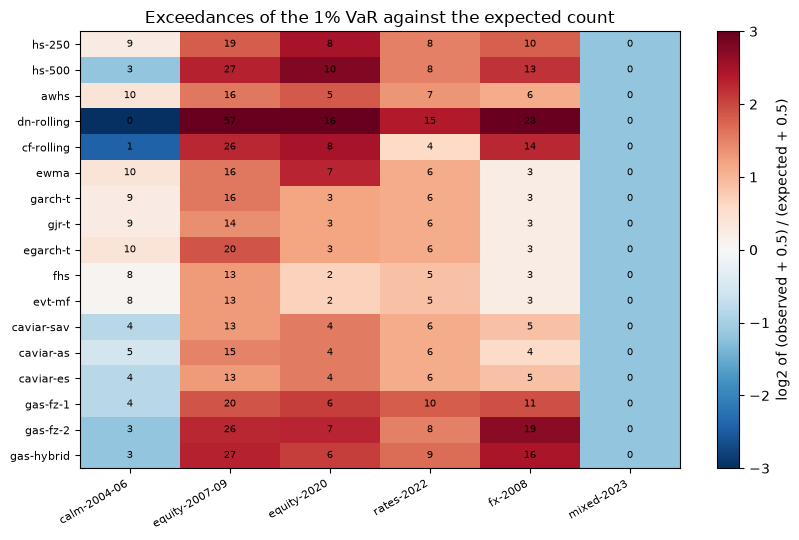

In [11]:
# Draw the ratio of observed to expected exceedances (rung by window), with the counts written in the cells
ratio = (counts + 0.5) / (expected + 0.5)               # a half-count offset keeps zero counts on the logarithmic scale
fig, ax = plt.subplots(figsize=(8.5, 5.5))
image = ax.imshow(np.log2(ratio), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(WINDOWS)))
ax.set_xticklabels(WINDOWS, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(rungs)))
ax.set_yticklabels(rungs, fontsize=8)
for i in range(len(rungs)):
    for j in range(len(WINDOWS)):
        ax.text(j, i, f"{int(counts[i, j])}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="log2 of (observed + 0.5) / (expected + 0.5)")
ax.set_title("Exceedances of the 1% VaR against the expected count")
fig.tight_layout()
plt.show()

## Results

- **The ladder.** It has 18 entries: 17 fitted rungs from historical simulation (R1) to the GAS-FZ models (R9), and `nn-fz` (R10), a neural challenger the bake records as not run. Nothing in the committed data says a neural model was evaluated.
- **No look-ahead.** In all six windows every estimation sample ends before its forecast day, and the hyperparameters were fixed on 1995-01-01 to 2003-12-31, before every window, with `tuned_on_test_window` false. These are checks on the committed file, not promises in a document.
- **Age weighting and the tail.** With $\lambda = 0.99$ and $K = 100$ the effective number of days is 92.4 of 100. At 2.5 percent the equally weighted forecast is 0.020861 for the VaR and 0.021771 for the ES, the age-weighted 0.021324 and 0.021933. At 1 percent on 100 days the tail is one observation, so for equal weights the ES equals the VaR (0.022293 both): an ES needs a tail with several observations.
- **EWMA is reproduced.** The committed ES equals the delta-normal ES of the volatility implied by the committed VaR to 1e-10, and the recursion started at the first committed variance and fed the realised returns reproduces the 251 committed volatilities with a maximum relative difference of 5.9e-9, which is the rounding of the file. With $\lambda = 0.97$ the weight falls under 1 percent after 151.2 days. The volatility rises from 0.0063 to 0.0146 (day 119) in the crisis, more than double, which is what a fixed 250-day window cannot do quickly.
- **Normal against Cornish-Fisher against the sample.** The returns are right-skewed (0.629) with excess kurtosis 2.129. At 1 percent the VaR is 0.025085 under the normal, 0.023873 with Cornish-Fisher and 0.023915 empirically; at 2.5 percent they are 0.021198, 0.018974 and 0.020861. The correction helps at 1 percent and overshoots at 2.5 percent: it is a moment fit, not a better model, and the expansion was valid in both cases.
- **Filtered historical simulation and EVT on EWMA residuals.** The standardised residuals have a standard deviation of 1.070 and a minimum of -3.590. At 1 percent the next-day VaR (ES) is 0.02054 (0.02353) normal, 0.02353 (0.02702) filtered historical simulation and 0.02152 (0.02701) EVT. The GPD shape depends on the threshold: 0.452 with 10 exceedances, 0.235 with 13, 0.045 with 20 and -0.027 with 25, so the tail index changes sign inside the range a practitioner would try. With 251 days a 5 percent threshold leaves 13 exceedances; the hyperparameter is a model risk, not a detail.
- **The fits that cannot be repeated here.** GARCH-t recorded 105 convergence failures in 504 refits in `equity-2007-09`, 100 in 251 in `fx-2008` and 51 in 64 in `mixed-2023`; GAS-FZ with two factors recorded 45 failures in 92 fits in `calm-2004-06` and 14 in 29 in `fx-2008`. CAViaR and GAS-FZ are fitted at each tail level, so their counts are twice the number of refit dates. Median GARCH-t parameters in the crisis: $\alpha_1$ 0.0598, $\beta_1$ 0.9189, $\nu$ 8.40.
- **The ladder against the windows.** The gates removed 6, 17, 13, 13, 7 and 0 of the 17 rungs in the six windows. In `equity-2007-09` all 17 exceed their 1 percent VaR more than 2.5 times the expected 5.0 (13 to 57 exceedances). In the calm window the gates remove rungs for the opposite reason: `dn-rolling` has 0 exceedances against 7.5 expected, and the three GAS-FZ rungs 3 to 4. In `fx-2008` six rungs (EWMA, the three GARCH, FHS and EVT) have 3 against 2.5 expected, and the three GAS-FZ rungs 11, 19 and 16.

What this notebook does not show: whether a count is statistically compatible with its expected value (notebook 03), the ES forecasts (notebook 04), or which eligible rung forecasts best (notebook 05).

## Summary

- The ladder is a sequence of estimators with a known source, innovation and refit schedule; the committed document also records the challenger it does not run.
- Two properties of an honest back-test are checkable from the committed files: every estimation sample ends before its forecast day, and the hyperparameters were fixed before every window.
- The closed-form rungs can be run and checked on real returns with the engine's functions; a committed EWMA forecast is reproduced by its own recursion to rounding, which is the kind of check any committed forecast should pass.
- GARCH, CAViaR and GAS-FZ need a package or a sample size a notebook on committed files does not have; their evidence is the committed forecasts and the record of their refits and convergence failures.
- No rung wins everywhere: coverage depends on the window, and the gates remove many rungs in the crisis windows.

**What to try next.** Change the threshold fraction in step 6 and watch the shape $\hat\xi$ and the EVT VaR move; then read notebook 03 to see how the exceedance counts above are tested.

## References

- Pritsker, M. (2001), The hidden dangers of historical simulation, Federal Reserve Board FEDS 2001-27. https://www.federalreserve.gov/Pubs/feds/2001/200127/200127pap.pdf
- Boudoukh, J., Richardson, M. and Whitelaw, R. (1998), The best of both worlds, Risk 11(5). https://pages.stern.nyu.edu/~rwhitela/papers/hybrid%20risk98.pdf
- J.P. Morgan/Reuters (1996), RiskMetrics Technical Document, 4th ed., section 5.3.2. https://www.msci.com/documents/10199/5915b101-4206-4ba0-aee2-3449d5c7e95a
- Cornish, E. A. and Fisher, R. A. (1938), Moments and cumulants in the specification of distributions, Revue de l'Institut International de Statistique 5(4). https://doi.org/10.2307/1400905
- Bollerslev, T. (1986), Generalized autoregressive conditional heteroskedasticity, Journal of Econometrics 31(3). https://doi.org/10.1016/0304-4076(86)90063-1
- Glosten, L. R., Jagannathan, R. and Runkle, D. E. (1993), On the relation between the expected value and the volatility of the nominal excess return on stocks, Journal of Finance 48(5). https://doi.org/10.1111/j.1540-6261.1993.tb05128.x
- Nelson, D. B. (1991), Conditional heteroskedasticity in asset returns: a new approach, Econometrica 59(2). https://doi.org/10.2307/2938260
- McNeil, A. J. and Frey, R. (2000), Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach, Journal of Empirical Finance 7(3-4). https://doi.org/10.1016/S0927-5398(00)00012-8
- Engle, R. F. and Manganelli, S. (2004), CAViaR: conditional autoregressive value at risk by regression quantiles, Journal of Business and Economic Statistics 22(4). https://doi.org/10.1198/073500104000000370
- Taylor, J. W. (2019), Forecasting value at risk and expected shortfall using a semiparametric approach based on the asymmetric Laplace distribution, Journal of Business and Economic Statistics 37(1). https://doi.org/10.1080/07350015.2017.1281815
- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Hull, J. and White, A. (1998), Incorporating volatility updating into the historical simulation method for value-at-risk, Journal of Risk 1(1). https://doi.org/10.21314/JOR.1998.001
- Barone-Adesi, G., Giannopoulos, K. and Vosper, L. (1999), VaR without correlations for portfolios of derivative securities, Journal of Futures Markets 19(5).